Scratch: fine details (exploration, not a decision)

This notebook compares V2 with the current support set at three input sizes: 1024 (native), 1152 (largest training resolution of C-RADIOv4, tech report Sect. 2.2) and 2048 (a 2x zoom of the whole frame, used as a proxy for a second look at each object). Prototypes are rebuilt at each size.

Frames, chosen before looking: every arm frame of the validation set and the loose mouth seen from the side.

Criterion, written before running. A size is worth a study if, on these frames, the two loose arms on the table take two different and correct labels, the arm being picked or mounted takes its own label, and the other pieces do not get visibly worse. The side view of the mouth is looked at, but not required.

These frames belong to the development set, so this is exploration. A size that passes goes to the decision rule on the 32 validation frames.

In [ ]:
# 1 Imports, paths and shared module
%load_ext autoreload
%autoreload 2
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
ANNOTATION_ARCHIVE = PROJECT_ROOT / "data" / "annotation_versions" / "margin_study"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "scratch" / "fine_details"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

from perception.classes import CLASS_NAMES, HAND_LABEL, PIECE_LABELS
from perception.features import FeatureExtractor
from perception.labels import sequence_of, rasterize_annotation, patch_label_grid
from perception.prototypes import patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels
from perception.metrics import confusion_matrix, frame_iou, frame_miou
from perception.visualization import render_overlay

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
# 2 Configuration
DEVICE = "cuda"
PATCH_SIZE = 16                      # patch size of C-RADIOv4
MIN_LABEL_COVERAGE = 0.5             # labelling rule of the pipeline (Section 5)
MARGIN = 0.0                         # background margin of V2 (margin study, Section 9)
GT_LABELS = PIECE_LABELS | {HAND_LABEL}
RESOLUTIONS = [1024, 1152, 2048]     # native; largest training size (tech report Sect. 2.2); 2x zoom as proxy for a second look
ROW_CHUNK = 2048                     # patches per GPU block for the similarities: bounds memory, does not change the result
TEST_SEQUENCES = {"assembly_1"}

# Frames chosen before looking; FOCUS = pieces the crop of Section 5 is centred on
FRAMES = {
    "assembly_2_f0005": ("table: loose mouth seen from the side", ["mouth"]),
    "assembly_2_f0057": ("table: both arms loose",                ["arm_1", "arm_2"]),
    "assembly_2_f0059": ("pick: arm_1",                           ["arm_1"]),
    "assembly_2_f0060": ("mount: arm_1",                          ["arm_1"]),
    "assembly_2_f0063": ("pick: arm_2",                           ["arm_2"]),
    "assembly_2_f0065": ("mount: arm_2",                          ["arm_2"]),
    "assembly_2_f0068": ("table: both arms mounted",              ["arm_1", "arm_2"]),
}

# Current support set: the 10 frames of the multi-prototype and margin studies, in the same order,
# with the annotations used there (phase_1_support_set_v2_study.ipynb, cell 2.5).
# caos_f0211 was completed in v1.7, so its old annotation is read from the archive.
CURRENT_SUPPORT = [
    {"frame": "5_assembled_f0002",            "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "use_labels": {HAND_LABEL},
     "json_path": ANNOTATION_ARCHIVE / "caos_f0211.json"},
    {"frame": "4_partially_assembled_f0002",  "use_labels": {"body", "mouth"}},
    {"frame": "caos_f0043",                   "use_labels": {"mouth"}},
]
assert len(CURRENT_SUPPORT) == 10, "The support set must have the 10 frames of v1.7"

for item in CURRENT_SUPPORT:
    assert sequence_of(item["frame"]) not in TEST_SEQUENCES | {"assembly_2"}, f"Leakage: {item['frame']}"
    item["image_path"] = FRAMES_DIR / f"{item['frame']}.jpg"
    item["json_path"] = item.get("json_path") or FRAMES_DIR / f"{item['frame']}.json"
for frame in FRAMES:
    assert sequence_of(frame) not in TEST_SEQUENCES

extractor = FeatureExtractor(MODEL_DIR, device=DEVICE)

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

In [7]:
# 3 V2 at each resolution: prototypes from the support set, predictions on the chosen frames
def patch_labels(json_path, use_labels, size):
    """Patch labels of one annotation on the grid of the given input size (rule of the pipeline)."""
    return patch_label_grid(rasterize_annotation(json_path, use_labels, size), PATCH_SIZE, MIN_LABEL_COVERAGE)[0]


def similarities_in_blocks(features, prototypes, owners):
    """class_similarities_gpu on blocks of ROW_CHUNK patches. Each patch is independent: same result, bounded memory."""
    flat = features.reshape(-1, features.shape[-1])
    blocks = [class_similarities_gpu(flat[i:i + ROW_CHUNK], prototypes, owners) for i in range(0, len(flat), ROW_CHUNK)]
    return np.concatenate(blocks).reshape(*features.shape[:-1], -1)


RESULTS = {}
for resolution in RESOLUTIONS:
    prototypes_gpu = owners_gpu = None
    try:
        refs = []
        for item in CURRENT_SUPPORT:
            features, size = extractor.extract(Image.open(item["image_path"]).convert("RGB"), resolution)
            refs.append({"features": features, "patch_labels": patch_labels(item["json_path"], item["use_labels"], size)})
        prototypes, owners = sort_by_class(*patch_prototypes(refs))
        del refs
        if resolution == 1024:
            assert len(owners) == 39125, "At 1024 the prototypes must be those of the support-set study on V2 (Section 4.2)"
        prototypes_gpu = torch.as_tensor(prototypes, device=DEVICE)
        owners_gpu = torch.as_tensor(owners, device=DEVICE)
        for frame in FRAMES:
            start = time.perf_counter()
            features, size = extractor.extract(Image.open(FRAMES_DIR / f"{frame}.jpg").convert("RGB"), resolution)
            labels = assign_labels(similarities_in_blocks(features, prototypes_gpu, owners_gpu), MARGIN)
            torch.cuda.synchronize()
            RESULTS[(resolution, frame)] = {"labels": labels, "seconds": time.perf_counter() - start,
                                            "gt": patch_labels(FRAMES_DIR / f"{frame}.json", GT_LABELS, size)}
        print(f"{resolution}: input {size}, grid {labels.shape}, {len(owners)} prototypes")
    except torch.cuda.OutOfMemoryError:
        print(f"{resolution}: out of GPU memory, skipped")
    finally:
        del prototypes_gpu, owners_gpu
        torch.cuda.empty_cache()

1024: input (1024, 1024), grid (64, 64), 39125 prototypes
1152: input (1152, 1152), grid (72, 72), 49606 prototypes
2048: input (2048, 2048), grid (128, 128), 158055 prototypes


In [8]:
# 4 Where the arm patches go, and a summary on these frames (each resolution on its own grid: description only)
ARM_IDS = {"arm_1": CLASS_NAMES.index("arm_1"), "arm_2": CLASS_NAMES.index("arm_2")}
rows = []
for (resolution, frame), r in RESULTS.items():
    for arm, arm_id in ARM_IDS.items():
        mask = r["gt"] == arm_id
        if mask.any():
            pred = r["labels"][mask]
            rows.append({"frame": frame[-5:], "moment": FRAMES[frame][0], "arm": arm, "resolution": resolution,
                         "patches": int(mask.sum()),
                         "as arm_1": int((pred == ARM_IDS["arm_1"]).sum()),
                         "as arm_2": int((pred == ARM_IDS["arm_2"]).sum()),
                         "other": int((~np.isin(pred, list(ARM_IDS.values()))).sum())})
display(pd.DataFrame(rows).set_index(["frame", "arm", "resolution"]).sort_index())

summary = []
for resolution in RESOLUTIONS:
    keys = [key for key in RESULTS if key[0] == resolution]
    if not keys:
        continue
    confusions = [confusion_matrix(RESULTS[key]["gt"], RESULTS[key]["labels"]) for key in keys]
    excluded = [set() for _ in keys]
    iou = frame_iou(confusions, excluded)
    summary.append({"resolution": resolution,
                    "mIoU 10 pieces": frame_miou(confusions, excluded),
                    "mIoU arms merged": frame_miou(confusions, excluded, merge=True),
                    **{name: iou[CLASS_NAMES.index(name)] for name in ["arm_1", "arm_2", "mouth", "nose"]},
                    "s per frame (median)": np.median([RESULTS[key]["seconds"] for key in keys])})
display(pd.DataFrame(summary).set_index("resolution").round(3))

moment  patches  \
frame arm   resolution                                                   
f0005 arm_1 1024        table: loose mouth seen from the side        2   
            1152        table: loose mouth seen from the side        3   
            2048        table: loose mouth seen from the side       10   
      arm_2 1024        table: loose mouth seen from the side        8   
            1152        table: loose mouth seen from the side       10   
            2048        table: loose mouth seen from the side       31   
f0057 arm_1 1024                       table: both arms loose       11   
            1152                       table: both arms loose       15   
            2048                       table: both arms loose       48   
      arm_2 1024                       table: both arms loose        8   
            1152                       table: both arms loose        8   
            2048                       table: both arms loose       33   
f0059 arm_1 1024                                  pick: arm_1        6   
            1152                                  pick: arm_1        6   
            2048                                  pick: arm_1       23   
      arm_2 1024                                  pick: arm_1        2   
            1152                                  pick: arm_1        2   
            2048                                  pick: arm_1        6   
f0060 arm_1 1024                                 mount: arm_1       10   
            1152                                 mount: arm_1        9   
            2048                                 mount: arm_1       27   
      arm_2 1024                                 mount: arm_1        3   
            1152                                 mount: arm_1        6   
            2048                                 mount: arm_1       20   
f0063 arm_1 1024                                  pick: arm_2        7   
            1152                                  pick: arm_2        8   
            2048                                  pick: arm_2       24   
      arm_2 1024                                  pick: arm_2        6   
            1152                                  pick: arm_2        8   
            2048                                  pick: arm_2       21   
f0065 arm_1 1024                                 mount: arm_2        6   
            1152                                 mount: arm_2        9   
            2048                                 mount: arm_2       23   
      arm_2 1024                                 mount: arm_2        1   
            1152                                 mount: arm_2        2   
            2048                                 mount: arm_2        4   
f0068 arm_1 1024                     table: both arms mounted        6   
            1152                     table: both arms mounted        7   
            2048                     table: both arms mounted       29   
      arm_2 1024                     table: both arms mounted        6   
            1152                     table: both arms mounted        7   
            2048                     table: both arms mounted       20   

                        as arm_1  as arm_2  other  
frame arm   resolution                             
f0005 arm_1 1024               0         0      2  
            1152               3         0      0  
            2048               1         8      1  
      arm_2 1024               0         3      5  
            1152               0         5      5  
            2048               1        19     11  
f0057 arm_1 1024              11         0      0  
            1152              15         0      0  
            2048              47         0      1  
      arm_2 1024               1         7      0  
            1152               5         2      1  
            2048              19         4     10  
f0059 arm_1 1024               0         0      6  
            1152  

,mIoU 10 pieces,mIoU arms merged,arm_1,arm_2,mouth,nose,s per frame (median)
resolution,,,,,,,
1024,0.791,0.826,0.722,0.500,0.692,0.754,0.453
1152,0.772,0.814,0.761,0.372,0.657,0.766,0.660
2048,0.788,0.843,0.683,0.318,0.673,0.848,4.650


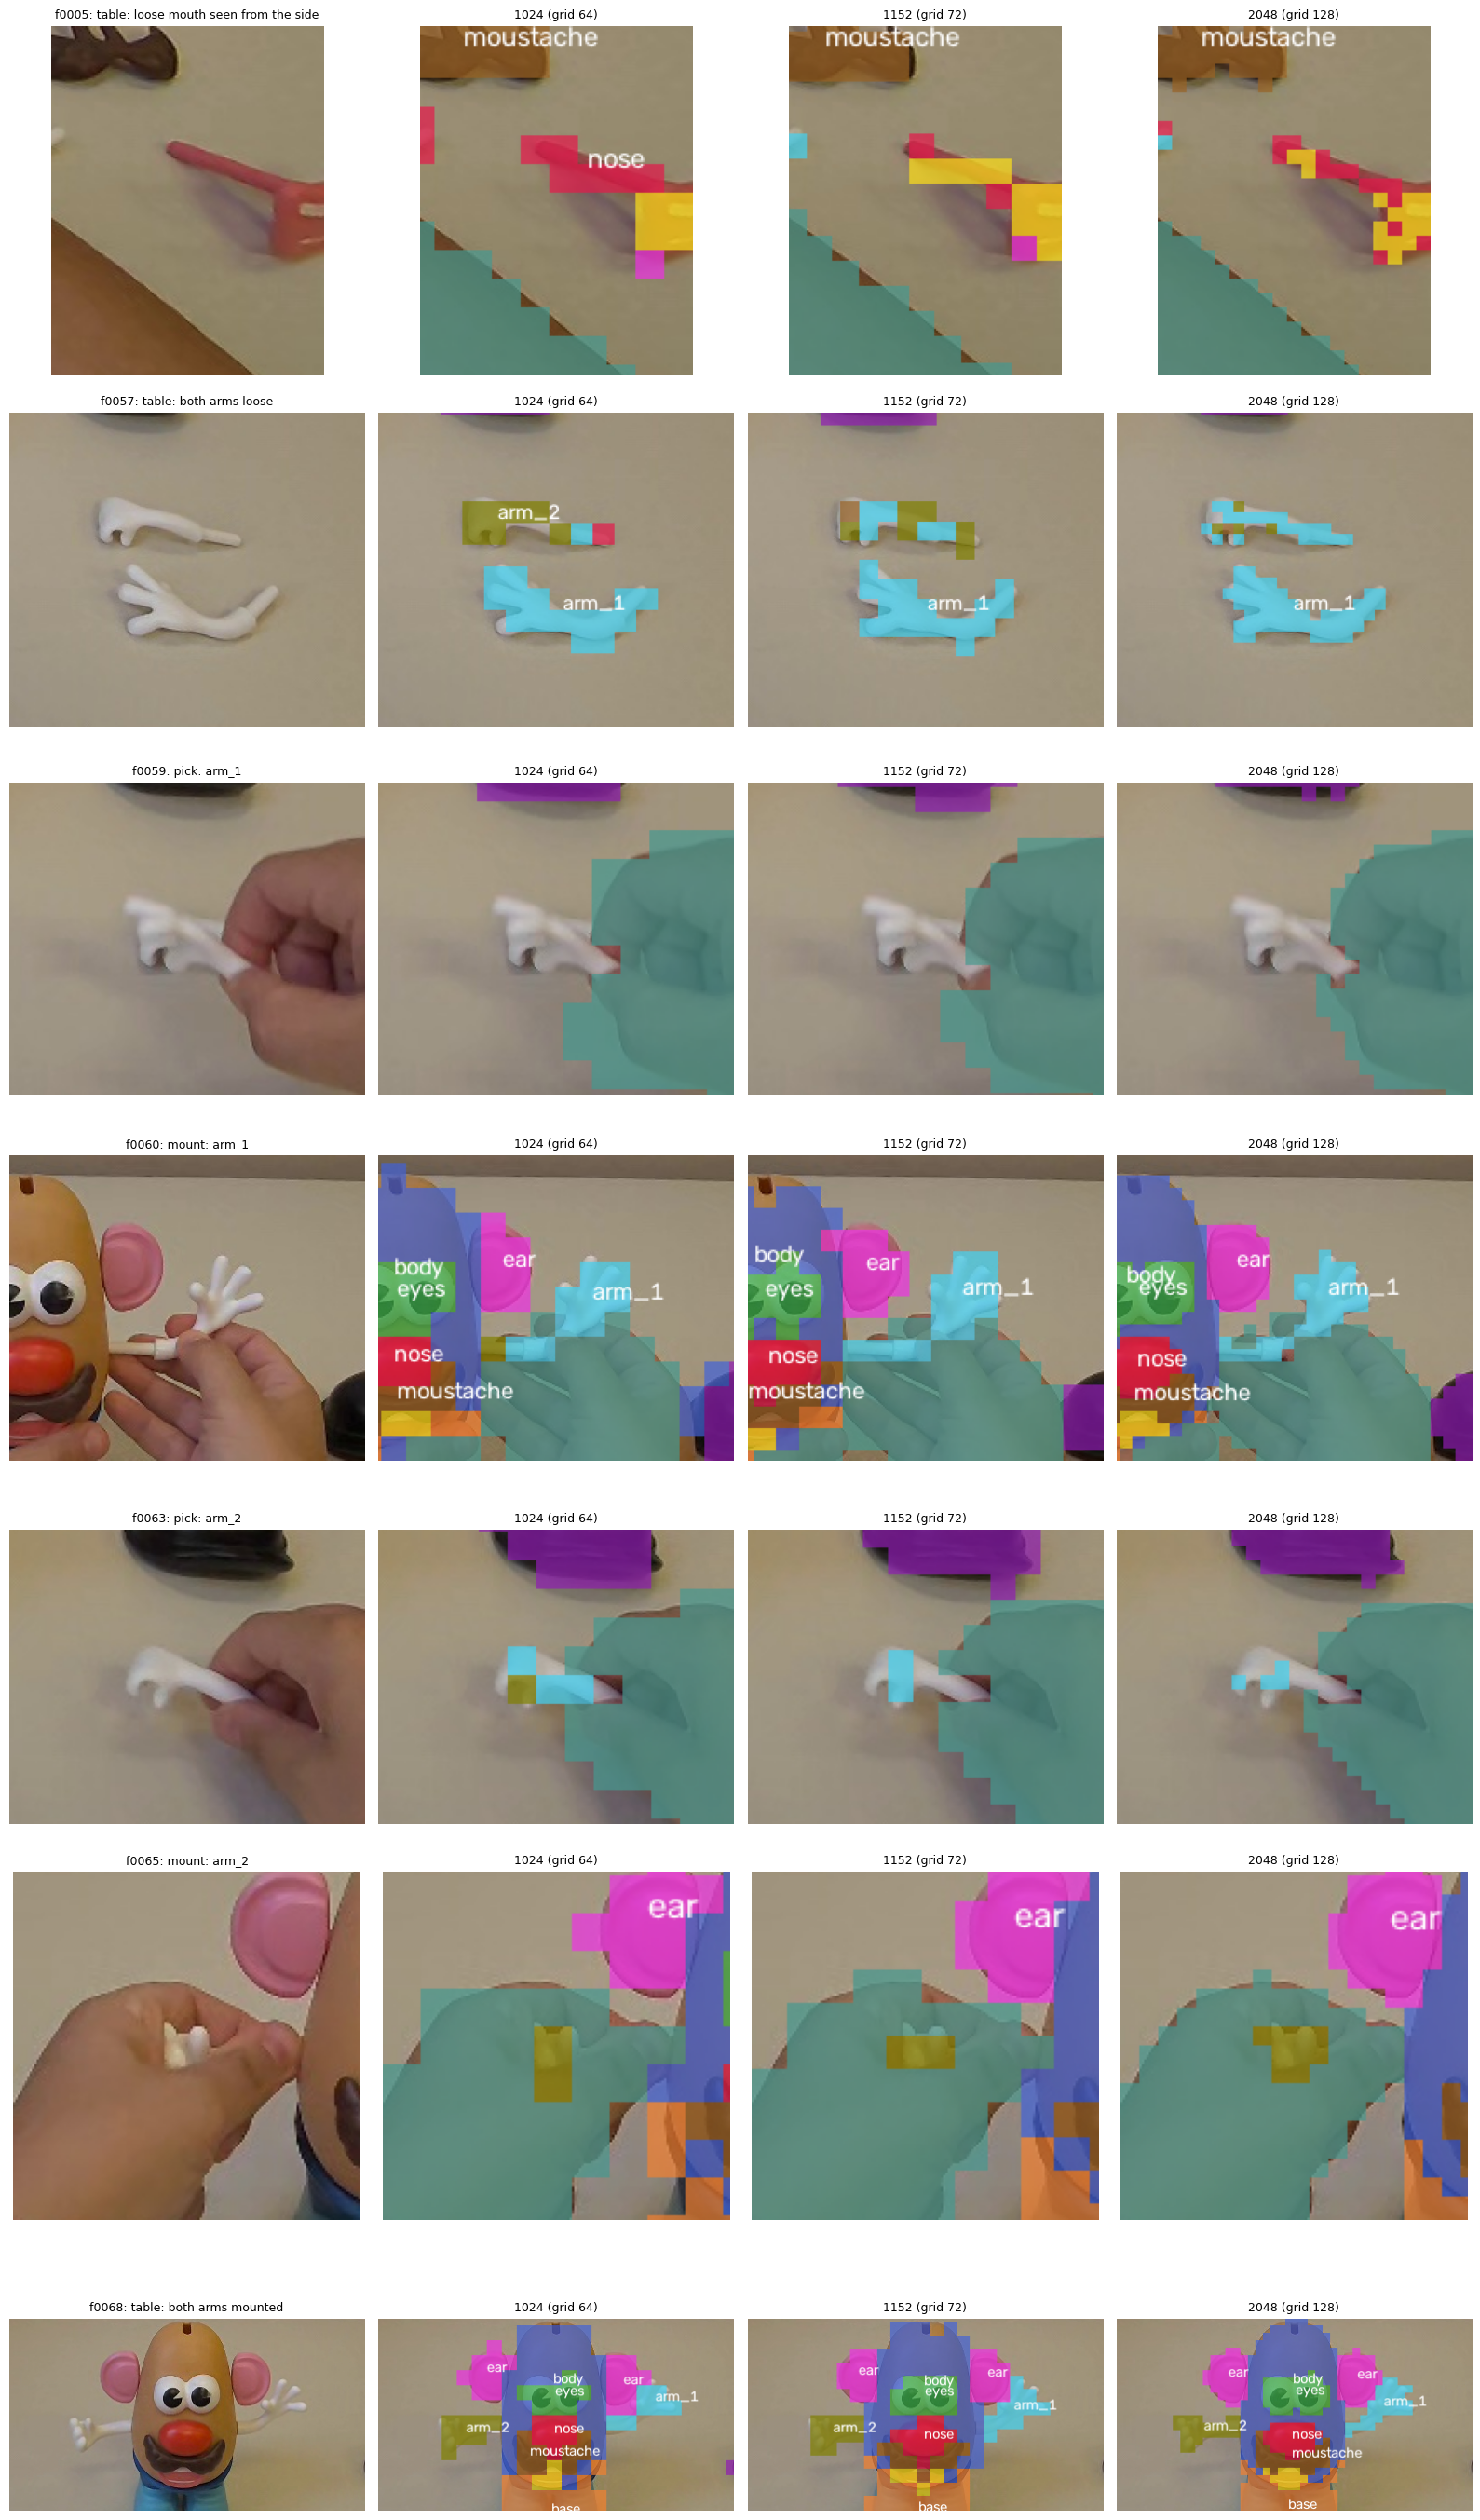

In [9]:
# 5 The three resolutions side by side, cropped around the pieces of each frame
PAD = 64   # pixels of context around the focus pieces
fig, axes = plt.subplots(len(FRAMES), len(RESOLUTIONS) + 1, figsize=(4 * (len(RESOLUTIONS) + 1), 4 * len(FRAMES)))
for row, (frame, (moment, focus)) in zip(axes, FRAMES.items()):
    image = np.array(Image.open(FRAMES_DIR / f"{frame}.jpg").convert("RGB"))
    focus_map = rasterize_annotation(FRAMES_DIR / f"{frame}.json", set(focus), (image.shape[1], image.shape[0]))
    ys, xs = np.nonzero(np.isin(focus_map, [CLASS_NAMES.index(name) for name in focus]))
    if len(ys):
        y0, y1 = max(ys.min() - PAD, 0), min(ys.max() + PAD, image.shape[0])
        x0, x1 = max(xs.min() - PAD, 0), min(xs.max() + PAD, image.shape[1])
    else:
        y0, y1, x0, x1 = 0, image.shape[0], 0, image.shape[1]
    row[0].imshow(image[y0:y1, x0:x1])
    row[0].set_title(f"{frame[-5:]}: {moment}", fontsize=9)
    for ax, resolution in zip(row[1:], RESOLUTIONS):
        r = RESULTS.get((resolution, frame))
        if r is None:
            ax.set_title(f"{resolution}: not run")
            continue
        grid = r["labels"].shape[0]
        overlay = render_overlay(image, r["labels"], min_blob_patches=max(1, round(5 * (grid / 64) ** 2)))
        ax.imshow(overlay[y0:y1, x0:x1])
        ax.set_title(f"{resolution} (grid {grid})", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fine_details_crops.png", dpi=120)
plt.show()

Observation 5: At 1024 the two loose arms of f0057 take their own labels (arm_1 11 of 11, arm_2 7 of 8). At 1152 and 2048 arm_2 is mostly taken for arm_1 (2 of 8 and 4 of 33 correct). In f0005 the loose arms at 2048 both tend to arm_2 (arm_1 taken for arm_2 in 8 of 10 patches). No size gives both loose arms their own label in both frames.

arm_1 in hand (f0059) is never recognized: all its patches go to other classes at every size (6, 6 and 23). arm_2 in hand (f0063) is mostly other or arm_1, worse at 2048 (17 of 21 other). Mounted arms are correct at every size.

Over the 7 frames the mIoU over 10 pieces is 0.791, 0.772 and 0.788, and arm_2 drops from 0.500 to 0.372 and 0.318; the nose rises to 0.848 at 2048. These values are on each size's own grid and are descriptive. Perception takes about 0.45, 0.66 and 4.7 s per frame.

By the criterion written before running, neither 1152 nor 2048 is worth a study. Hypothesis: more pixels per arm do not separate the arms, since the support set shows arm_2 almost only from far away (support-set study on V2, Obs. 8.5); 2048 is also outside the training range of C-RADIOv4. This test does not separate the two causes.

In the figure, at 2048 the loose arm_2 of f0057 is mostly coloured as arm_1, and the arm in hand of f0059 stays uncoloured at every size.

Second look on annotated objects (exploration)

Each annotated object is cropped with a square of side 1024/3 (341 pixels), enlarged to 1024 and passed to C-RADIO, so the object is seen with about three times more pixels. A zoomed region no smaller than one third of the previous scale follows RA-CNN (Fu et al. 2017, Sect. 3.4), which constrains the attended square in this way to avoid losing the structure of the object. Larger objects get a larger crop, so that they fit.

Prototypes come from crops of the reference frames, made in the same way, with every labelled patch of the crop (piece, background, hand, nearby pieces). Crops of the chosen frames are centred on the annotated arms (and on the mouth in f0005), so the test measures whether the zoom tells the pieces apart once the box is right, not whether the piece is found.

Criterion, written before running: as in the first part, compared with 1024 on the same area.

In [10]:
# 6 Second look: crops of the reference frames around each annotated object, enlarged to 1024, as V2 prototypes
import cv2
from perception.labels import load_annotation

FRAME_SIZE = 1024
CROP_SIDE = round(FRAME_SIZE / 3)   # RA-CNN Sect. 3.4: the zoomed square is no smaller than one third of the previous scale


def crop_box(points, side=CROP_SIDE, size=FRAME_SIZE):
    """Square box centred on an object, of `side` pixels or larger if the object does not fit, kept inside the frame."""
    points = np.asarray(points)
    (x_min, y_min), (x_max, y_max) = points.min(axis=0), points.max(axis=0)
    s = int(np.ceil(min(max(side, x_max - x_min, y_max - y_min), size)))
    cx, cy = (x_min + x_max) / 2, (y_min + y_max) / 2
    x0 = int(np.clip(round(cx - s / 2), 0, size - s))
    y0 = int(np.clip(round(cy - s / 2), 0, size - s))
    return x0, y0, x0 + s, y0 + s


def crop_item(image_path, json_path, use_labels, box):
    """Features and patch labels of one crop enlarged to FRAME_SIZE; labels from the annotation cropped the same way."""
    image = Image.open(image_path).convert("RGB")
    assert image.size == (FRAME_SIZE, FRAME_SIZE)
    x0, y0, x1, y1 = box
    crop = image.crop(box).resize((FRAME_SIZE, FRAME_SIZE), Image.Resampling.LANCZOS)
    features, size = extractor.extract(crop)
    assert size == (FRAME_SIZE, FRAME_SIZE)
    pixel_map = rasterize_annotation(json_path, use_labels, (FRAME_SIZE, FRAME_SIZE))[y0:y1, x0:x1]
    pixel_map = cv2.resize(pixel_map, (FRAME_SIZE, FRAME_SIZE), interpolation=cv2.INTER_NEAREST)
    return features, patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)[0], crop


crop_refs = []
for item in CURRENT_SUPPORT:
    for shape in load_annotation(item["json_path"])["shapes"]:
        if shape["label"] in item["use_labels"]:
            box = crop_box(shape["points"])
            features, labels, _ = crop_item(item["image_path"], item["json_path"], item["use_labels"], box)
            crop_refs.append({"features": features, "patch_labels": labels,
                              "frame": item["frame"], "piece": shape["label"], "side": box[2] - box[0]})
CROP_V2_CPU = sort_by_class(*patch_prototypes(crop_refs))
print(f"{len(crop_refs)} crops; sides from {min(r['side'] for r in crop_refs)} to {max(r['side'] for r in crop_refs)} pixels")
display(pd.Series(np.bincount(CROP_V2_CPU[1], minlength=len(CLASS_NAMES)), index=CLASS_NAMES).to_frame("prototypes").T)
for ref in crop_refs:
    ref.pop("features")   # free memory: only the prototypes are needed from here on
CROP_V2 = tuple(torch.as_tensor(a, device=DEVICE) for a in CROP_V2_CPU)

59 crops; sides from 341 to 457 pixels


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,186354,13027,6443,3604,2374,4230,2106,2877,1811,1884,1198,2717


In [11]:
# 7 Crops of the chosen frames around each focus object: zoomed V2 against 1024 on the same area
CONFUSER = {"arm_1": "arm_2", "arm_2": "arm_1", "mouth": "nose"}
grid_centres = np.arange(FRAME_SIZE // PATCH_SIZE) * PATCH_SIZE + PATCH_SIZE / 2


def counts(gt, labels, piece):
    """Patches of `piece` in the ground truth: total, correct, taken for its confuser, other."""
    pred = labels[gt == CLASS_NAMES.index(piece)]
    return {"patches": len(pred), "correct": int((pred == CLASS_NAMES.index(piece)).sum()),
            "confuser": int((pred == CLASS_NAMES.index(CONFUSER[piece])).sum()),
            "other": int((~np.isin(pred, [CLASS_NAMES.index(piece), CLASS_NAMES.index(CONFUSER[piece])])).sum())}


CROPS, rows = [], []
for frame, (moment, focus) in FRAMES.items():
    json_path = FRAMES_DIR / f"{frame}.json"
    for shape in load_annotation(json_path)["shapes"]:
        if shape["label"] not in focus:
            continue
        box = crop_box(shape["points"])
        start = time.perf_counter()
        features, gt, crop = crop_item(FRAMES_DIR / f"{frame}.jpg", json_path, GT_LABELS, box)
        labels = assign_labels(similarities_in_blocks(features, *CROP_V2), MARGIN)
        torch.cuda.synchronize()
        seconds = time.perf_counter() - start
        CROPS.append({"frame": frame, "piece": shape["label"], "box": box, "crop": crop, "labels": labels})
        x0, y0, x1, y1 = box
        inside = np.ix_((grid_centres >= y0) & (grid_centres < y1), (grid_centres >= x0) & (grid_centres < x1))
        base = RESULTS[(1024, frame)]
        for piece in [p for p in CONFUSER if p in focus]:
            zoom = counts(gt, labels, piece)
            native = counts(base["gt"][inside], base["labels"][inside], piece)
            if zoom["patches"] == 0 and native["patches"] == 0:
                continue
            rows.append({"frame": frame[-5:], "moment": moment, "crop on": shape["label"], "piece": piece,
                         "1024 patches": native["patches"],
                         "1024 share correct": native["correct"] / max(native["patches"], 1),
                         "1024 share confuser": native["confuser"] / max(native["patches"], 1),
                         "zoom patches": zoom["patches"],
                         "zoom share correct": zoom["correct"] / max(zoom["patches"], 1),
                         "zoom share confuser": zoom["confuser"] / max(zoom["patches"], 1),
                         "crop s": seconds})
display(pd.DataFrame(rows).set_index(["frame", "crop on", "piece"]).round(2))

moment  1024 patches  \
frame crop on piece                                                        
f0005 mouth   mouth  table: loose mouth seen from the side             7   
f0057 arm_2   arm_1                 table: both arms loose            11   
              arm_2                 table: both arms loose             8   
      arm_1   arm_1                 table: both arms loose            11   
              arm_2                 table: both arms loose             8   
f0059 arm_1   arm_1                            pick: arm_1             6   
f0060 arm_1   arm_1                           mount: arm_1            10   
              arm_1                           mount: arm_1            10   
f0063 arm_2   arm_2                            pick: arm_2             6   
f0065 arm_2   arm_2                           mount: arm_2             1   
f0068 arm_1   arm_1               table: both arms mounted             6   
              arm_2               table: both arms mounted             1   
      arm_2   arm_1               table: both arms mounted             1   
              arm_2               table: both arms mounted             6   

                     1024 share correct  1024 share confuser  zoom patches  \
frame crop on piece                                                          
f0005 mouth   mouth                0.57                 0.43            69   
f0057 arm_2   arm_1                1.00                 0.00           104   
              arm_2                0.88                 0.12            70   
      arm_1   arm_1                1.00                 0.00           105   
              arm_2                0.88                 0.12            70   
f0059 arm_1   arm_1                0.00                 0.00            47   
f0060 arm_1   arm_1                0.90                 0.10            59   
              arm_1                0.90                 0.10            70   
f0063 arm_2   arm_2                0.17                 0.50            46   
f0065 arm_2   arm_2                1.00                 0.00            12   
f0068 arm_1   arm_1                1.00                 0.00            60   
              arm_2                1.00                 0.00            12   
      arm_2   arm_1                1.00                 0.00            12   
              arm_2                1.00                 0.00            47   

                     zoom share correct  zoom share confuser  crop s  
frame crop on piece                                                   
f0005 mouth   mouth                0.78                 0.12    1.23  
f0057 arm_2   arm_1                1.00                 0.00    0.75  
              arm_2                0.59                 0.41    0.75  
      arm_1   arm_1                1.00                 0.00    0.74  
              arm_2                0.47                 0.51    0.74  
f0059 arm_1   arm_1                0.94                 0.02    0.74  
f0060 arm_1   arm_1                0.92                 0.07    0.72  
              arm_1                0.93                 0.06    0.73  
f0063 arm_2   arm_2                0.09                 0.89    0.76  
f0065 arm_2   arm_2                0.00                 0.00    0.75  
f0068 arm_1   arm_1                1.00                 0.00    0.76  
              arm_2                1.00                 0.00    0.76  
      arm_2   arm_1                1.00                 0.00    0.73  
              arm_2                1.00                 0.00    0.73

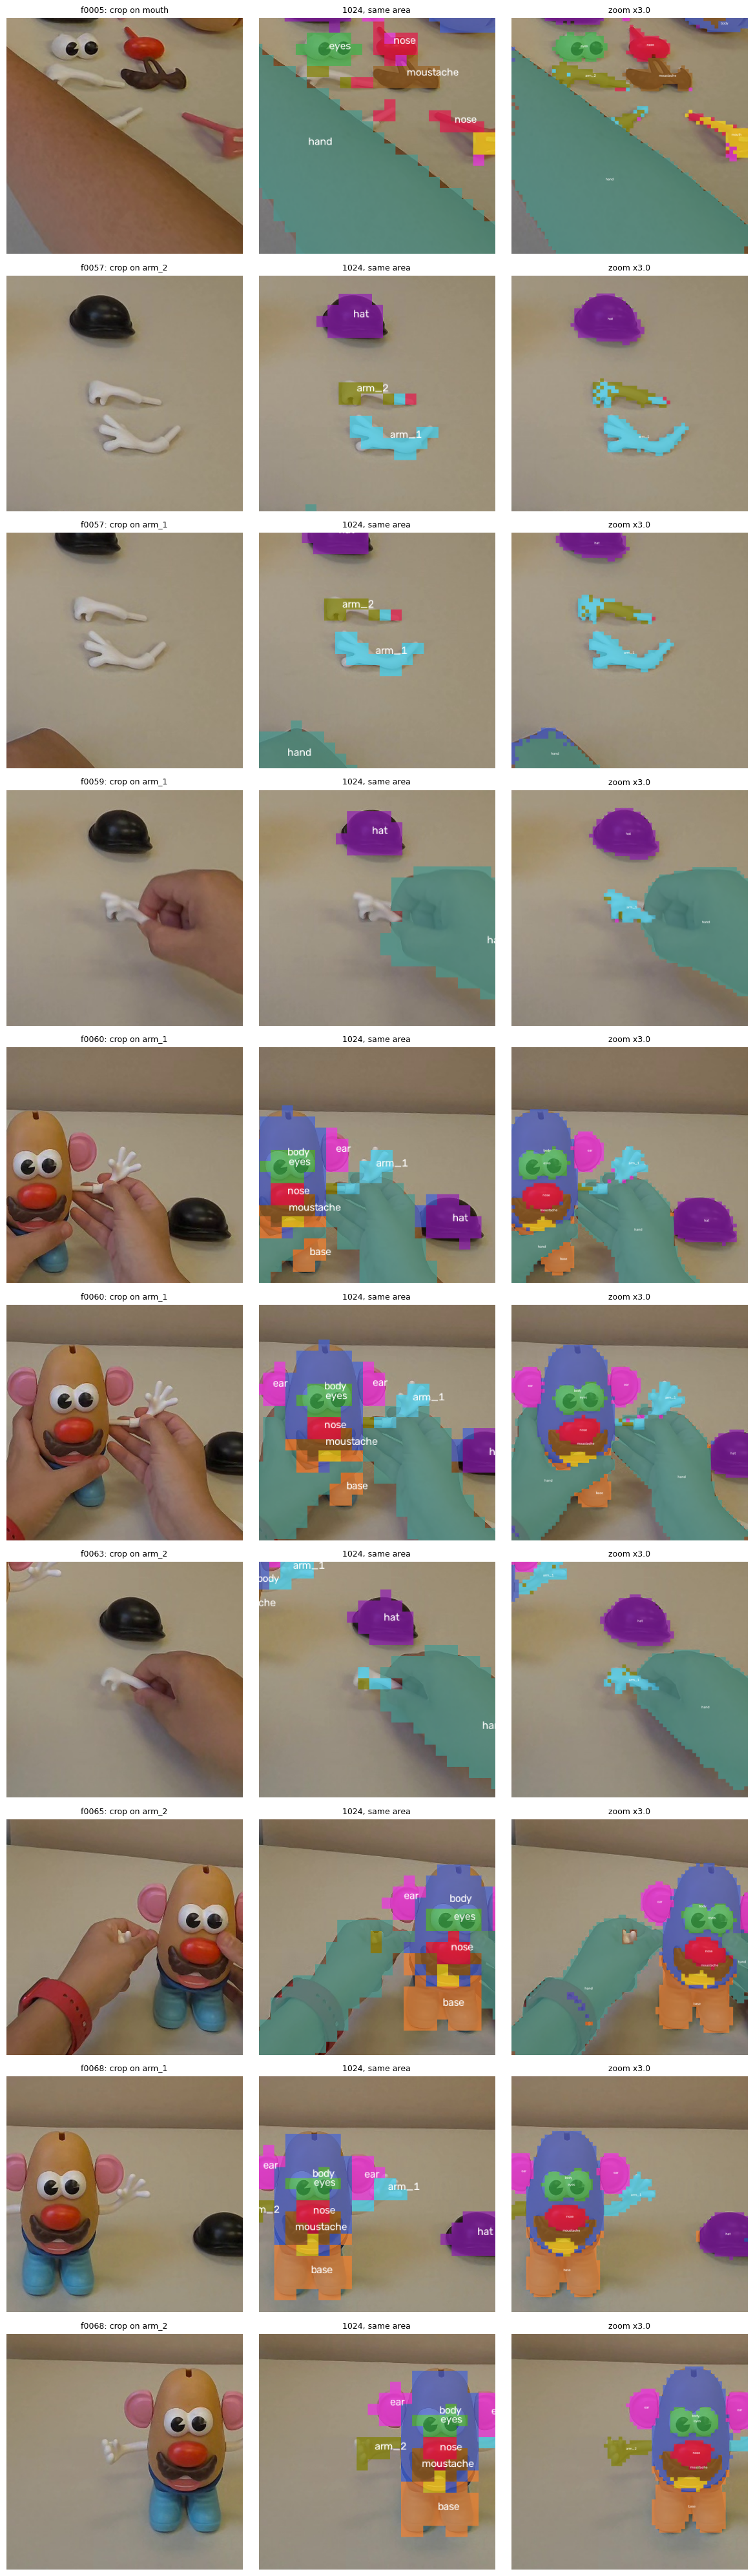

In [12]:
# 8 Each crop: original, 1024 predictions on the same area, zoomed predictions
fig, axes = plt.subplots(len(CROPS), 3, figsize=(12, 4 * len(CROPS)), squeeze=False)
for row, c in zip(axes, CROPS):
    x0, y0, x1, y1 = c["box"]
    image = np.array(Image.open(FRAMES_DIR / f"{c['frame']}.jpg").convert("RGB"))
    native = render_overlay(image, RESULTS[(1024, c["frame"])]["labels"], min_blob_patches=5)[y0:y1, x0:x1]
    zoom = render_overlay(np.array(c["crop"]), c["labels"], min_blob_patches=45)   # 5 patches at 1024 = about 45 at zoom x3
    row[0].imshow(c["crop"]); row[0].set_title(f"{c['frame'][-5:]}: crop on {c['piece']}", fontsize=9)
    row[1].imshow(native); row[1].set_title("1024, same area", fontsize=9)
    row[2].imshow(zoom); row[2].set_title(f"zoom x{FRAME_SIZE / (x1 - x0):.1f}", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "second_look_crops.png", dpi=120)
plt.show()

Observation 8: The crops of the reference frames give 59 crops (sides 341 to 457 pixels), with 1,884 prototypes for arm_1 and 1,198 for arm_2.

On the same areas, zoom x3 improves arm_1 and the mouth. arm_1 in hand (f0059) goes from 0.00 to 0.94 of its patches correct, and the mouth seen from the side (f0005) from 0.57 to 0.78, with nose falling from 0.43 to 0.12. arm_1 loose, mounted and in the complete figure stays between 0.90 and 1.00.

arm_2 gets worse. Loose (f0057) it falls from 0.88 to 0.47 and 0.59, taken for arm_1 in 0.41 to 0.51 of its patches. In hand (f0063) it falls from 0.17 to 0.09, with 0.89 taken for arm_1. Mounted under the hand (f0065), its 12 patches go to other classes. Mounted arms in the complete figure (f0068) stay correct. One crop takes about 0.75 s.

By the criterion, the second look does not pass: the loose arms no longer take two correct labels, and arm_2 gets worse at the pick and the mounting.

Hypothesis: the zoom adds information where a good example exists (arm_1 has one large example at working distance, caos_f0149), and not for arm_2, whose examples in the support set are small (support-set study on V2, Obs. 8.5). Boxes come from the ground truth, so the test does not include finding the piece.

Last test: second look with the arm examples already annotated

Same crops and zoom as above. The crop prototypes also get the arms annotated in frames already in the project but not used for arms: caos_f0043 (arm_2 loose) and caos_f0278 (arms mounted at working distance). Both arms are added wherever they are annotated, so the test does not favour one arm. No new annotation.

Decision, written before running. A blob takes the label of most of its patches, so a piece counts as recognized in a crop when more than half of its patches are correct. The second look is worth a study if arm_2 is recognized loose (f0057), in hand (f0063) and mounted (f0065), and arm_1 stays recognized wherever it was recognized with zoom alone. Otherwise Phase 1 closes at 1024 with the limit documented.

In [13]:
# 9 Crop prototypes with the arms annotated in caos_f0043 and caos_f0278 (both arms, wherever annotated)
EXTRA_ARMS = [
    {"frame": "caos_f0043", "use_labels": {"arm_1", "arm_2"}},   # in the support set only for the mouth
    {"frame": "caos_f0278", "use_labels": {"arm_1", "arm_2"}},   # candidate of the support-set study on V2
]
for item in EXTRA_ARMS:
    assert sequence_of(item["frame"]) not in TEST_SEQUENCES | {"assembly_2"}, f"Leakage: {item['frame']}"
    item["image_path"] = FRAMES_DIR / f"{item['frame']}.jpg"
    item["json_path"] = FRAMES_DIR / f"{item['frame']}.json"

extended_refs, added = [], []
for item in CURRENT_SUPPORT + EXTRA_ARMS:
    for shape in load_annotation(item["json_path"])["shapes"]:
        if shape["label"] in item["use_labels"]:
            box = crop_box(shape["points"])
            features, labels, _ = crop_item(item["image_path"], item["json_path"], item["use_labels"], box)
            extended_refs.append({"features": features, "patch_labels": labels})
            if item in EXTRA_ARMS:
                added.append({"frame": item["frame"], "piece": shape["label"], "side": box[2] - box[0],
                              "patches of the piece": int((labels == CLASS_NAMES.index(shape["label"])).sum())})
display(pd.DataFrame(added))
EXTENDED_V2_CPU = sort_by_class(*patch_prototypes(extended_refs))
del extended_refs
display(pd.Series(np.bincount(EXTENDED_V2_CPU[1], minlength=len(CLASS_NAMES)), index=CLASS_NAMES).to_frame("prototypes").T)
EXTENDED_V2 = tuple(torch.as_tensor(a, device=DEVICE) for a in EXTENDED_V2_CPU)

,frame,piece,side,patches of the piece
0,caos_f0043,arm_1,341,57
1,caos_f0043,arm_2,341,64
2,caos_f0278,arm_2,341,60
3,caos_f0278,arm_1,341,85


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,195698,13027,6443,3604,2374,4230,2106,2877,1811,2085,1388,2717


In [14]:
# 10 Same crops: 1024, zoom, zoom with the arm examples; then the decision rule written above
rows, LAST = [], []
for frame, (moment, focus) in FRAMES.items():
    json_path = FRAMES_DIR / f"{frame}.json"
    for shape in load_annotation(json_path)["shapes"]:
        if shape["label"] not in focus:
            continue
        box = crop_box(shape["points"])
        features, gt, crop = crop_item(FRAMES_DIR / f"{frame}.jpg", json_path, GT_LABELS, box)
        zoom = assign_labels(similarities_in_blocks(features, *CROP_V2), MARGIN)
        extended = assign_labels(similarities_in_blocks(features, *EXTENDED_V2), MARGIN)
        LAST.append({"frame": frame, "piece": shape["label"], "box": box, "crop": crop, "zoom": zoom, "extended": extended})
        x0, y0, x1, y1 = box
        inside = np.ix_((grid_centres >= y0) & (grid_centres < y1), (grid_centres >= x0) & (grid_centres < x1))
        base = RESULTS[(1024, frame)]
        piece = shape["label"]                      # each piece is judged in the crop centred on it
        row = {"frame": frame[-5:], "moment": moment, "piece": piece}
        for name, (g, l) in {"1024": (base["gt"][inside], base["labels"][inside]),
                             "zoom": (gt, zoom), "zoom + examples": (gt, extended)}.items():
            c = counts(g, l, piece)
            row[f"{name} correct"] = c["correct"] / max(c["patches"], 1)
            row[f"{name} confuser"] = c["confuser"] / max(c["patches"], 1)
        rows.append(row)
last = pd.DataFrame(rows).set_index(["frame", "piece"])
display(last.round(2))

# Decision rule: recognized = more than half of the patches correct
arm_2_cases = last.loc[[("f0057", "arm_2"), ("f0063", "arm_2"), ("f0065", "arm_2")]]
arm_2_ok = bool((arm_2_cases["zoom + examples correct"] > 0.5).all())
arm_1_cases = last.xs("arm_1", level="piece")
arm_1_kept = bool((arm_1_cases.loc[arm_1_cases["zoom correct"] > 0.5, "zoom + examples correct"] > 0.5).all())
print(f"arm_2 recognized loose, in hand and mounted: {arm_2_ok}")
print(f"arm_1 still recognized wherever zoom alone recognized it: {arm_1_kept}")
print("Decision:", "the second look is worth a study" if arm_2_ok and arm_1_kept
      else "Phase 1 closes at 1024, limit documented")

moment  1024 correct  \
frame piece                                                        
f0005 mouth  table: loose mouth seen from the side          0.57   
f0057 arm_2                 table: both arms loose          0.88   
      arm_1                 table: both arms loose          1.00   
f0059 arm_1                            pick: arm_1          0.00   
f0060 arm_1                           mount: arm_1          0.90   
      arm_1                           mount: arm_1          0.90   
f0063 arm_2                            pick: arm_2          0.17   
f0065 arm_2                           mount: arm_2          1.00   
f0068 arm_1               table: both arms mounted          1.00   
      arm_2               table: both arms mounted          1.00   

             1024 confuser  zoom correct  zoom confuser  \
frame piece                                               
f0005 mouth           0.43          0.78           0.12   
f0057 arm_2           0.12          0.59           0.41   
      arm_1           0.00          1.00           0.00   
f0059 arm_1           0.00          0.94           0.02   
f0060 arm_1           0.10          0.92           0.07   
      arm_1           0.10          0.93           0.06   
f0063 arm_2           0.50          0.09           0.89   
f0065 arm_2           0.00          0.00           0.00   
f0068 arm_1           0.00          1.00           0.00   
      arm_2           0.00          1.00           0.00   

             zoom + examples correct  zoom + examples confuser  
frame piece                                                     
f0005 mouth                     0.78                      0.12  
f0057 arm_2                     0.80                      0.20  
      arm_1                     0.52                      0.48  
f0059 arm_1                     0.30                      0.68  
f0060 arm_1                     0.86                      0.14  
      arm_1                     0.83                      0.17  
f0063 arm_2                     0.91                      0.07  
f0065 arm_2                     0.00                      0.00  
f0068 arm_1                     1.00                      0.00  
      arm_2                     1.00                      0.00

arm_2 recognized loose, in hand and mounted: False
arm_1 still recognized wherever zoom alone recognized it: False
Decision: Phase 1 closes at 1024, limit documented


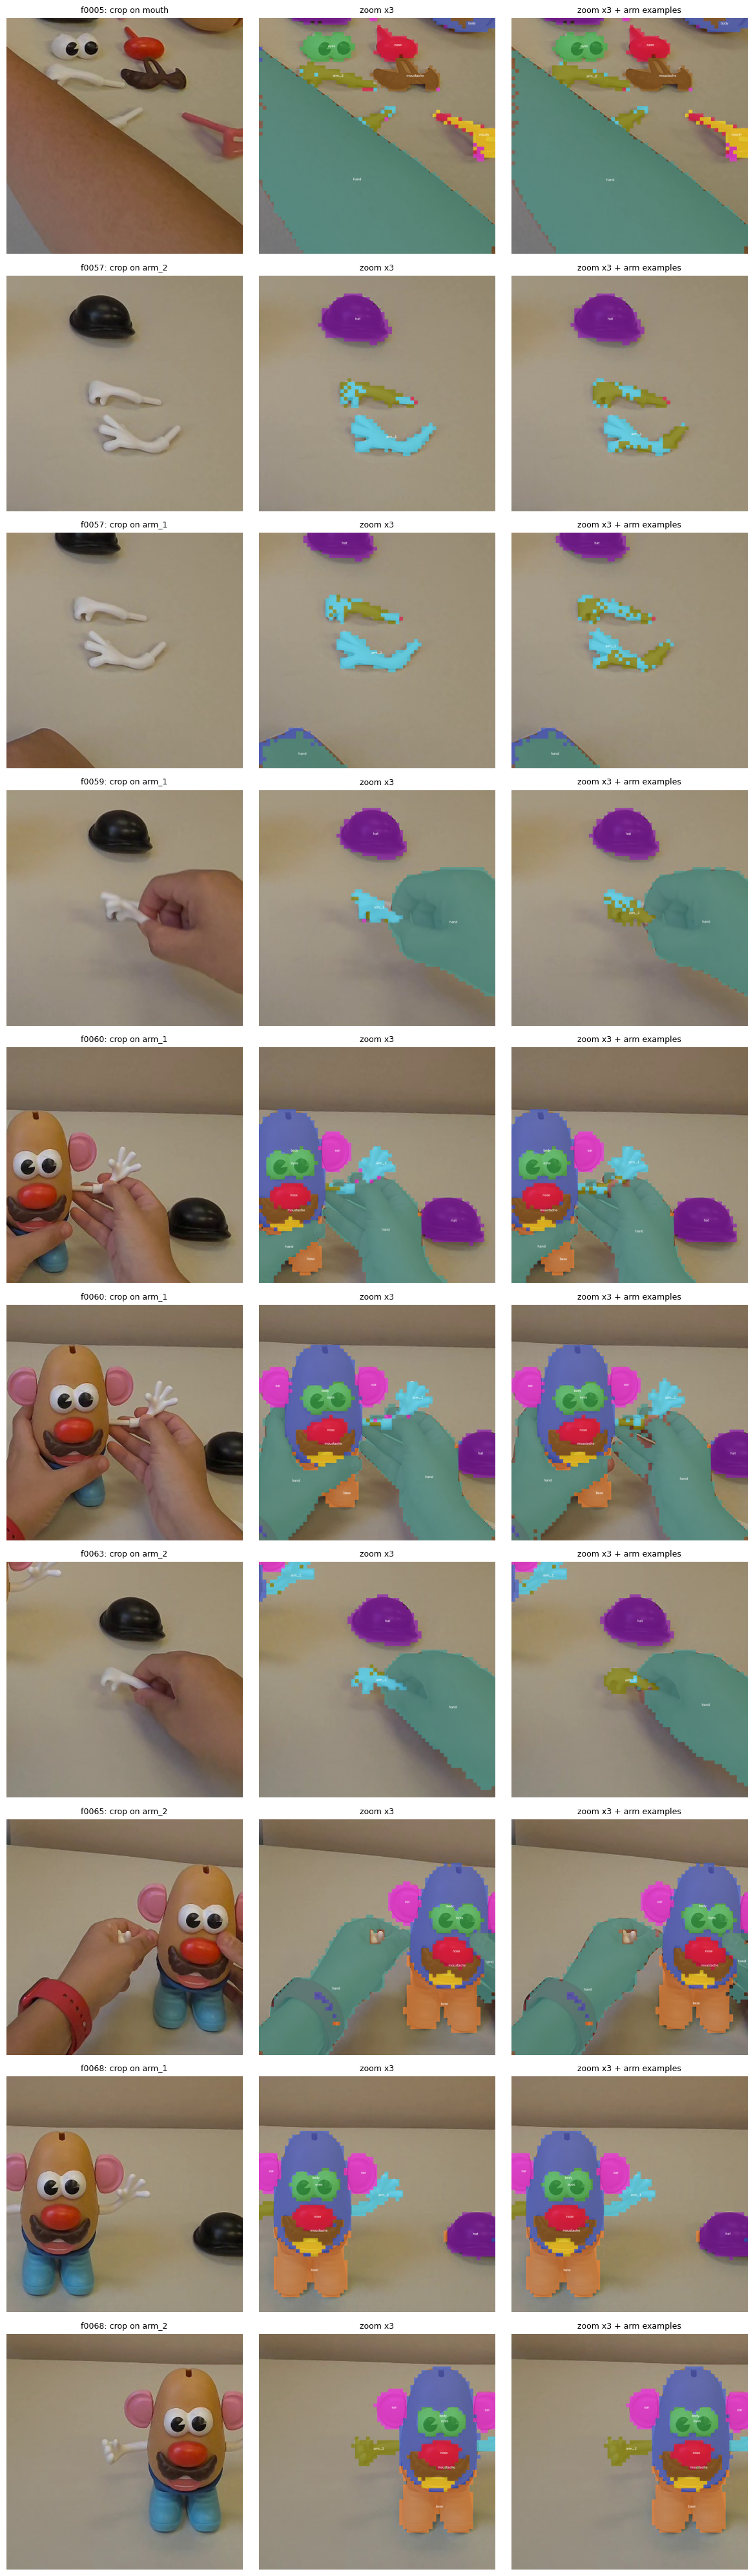

In [15]:
# 11 Each crop: original, zoom, zoom with the arm examples
fig, axes = plt.subplots(len(LAST), 3, figsize=(12, 4 * len(LAST)), squeeze=False)
for row, c in zip(axes, LAST):
    crop = np.array(c["crop"])
    row[0].imshow(crop); row[0].set_title(f"{c['frame'][-5:]}: crop on {c['piece']}", fontsize=9)
    row[1].imshow(render_overlay(crop, c["zoom"], min_blob_patches=45)); row[1].set_title("zoom x3", fontsize=9)
    row[2].imshow(render_overlay(crop, c["extended"], min_blob_patches=45)); row[2].set_title("zoom x3 + arm examples", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "second_look_extended.png", dpi=120)
plt.show()

Observation 11: The four added crops (caos_f0043 and caos_f0278, both arms) bring arm_1 to 2,085 and arm_2 to 1,388 prototypes.

With them, arm_2 improves loose (0.59 to 0.80) and in hand (0.09 to 0.91), but stays at 0.00 mounted under the hand (f0065). arm_1 gets worse: loose from 1.00 to 0.52, in hand from 0.94 to 0.30 (0.68 taken for arm_2), mounted from about 0.93 to about 0.85. The mouth and the complete figure do not change. By the rule written before running, Phase 1 closes at 1024.

Across the three tests the confusion moves from one arm to the other with the examples, as in the support-set study on V2 (Obs. 9.2). Hypothesis: most patches of an arm lie on its shaft, which is the same in both arms, so a patch-level nearest neighbour assigns them to whichever arm has the closest example. The identity lies in the hand of the arm, one or two areas of the piece, and a patch-level metric dilutes it. A decision at the level of the object, as in RA-CNN (Fu et al. 2017, Sect. 3.1 and 3.3), is a different question, not tested here.

-------------------------------------------------------------------------------------------------------------------------------------------

Conclusion

Three explorations were run on the frames of the arms and of the mouth: a larger input (1152 and 2048), a second look at each annotated object enlarged three times, and the same second look with the arm examples already annotated. None passed the criterion written before running, so the input stays at 1024.

A smaller patch is not possible with a frozen model: a standard ViT works well only at the patch size it was trained with (Beyer et al. 2023, Sect. 3.2). A grid shifted by half a patch gives denser outputs but no finer detail (Long et al. 2015, Sect. 3.2), so it was not run.

A larger input does not separate the arms and at 2048 costs about ten times more. The second look adds information where a good example exists: arm_1 in hand and the mouth seen from the side improve. arm_2 does not, and adding examples only moves the confusion from one arm to the other. As in the support-set study on V2, the examples of the support set decide more than the resolution.

Hypothesis: most patches of an arm lie on its shaft, which is the same in both arms, and the identity lies in a small part of the piece. Deciding the identity of an object as a whole, and keeping it over time, belongs to Phase 2.

These frames are development frames, so all values are optimistic.

-------------------------------------------------------------------------------------------------------------------------------------------

References

Beyer, L. et al. (2023). FlexiViT: One Model for All Patch Sizes. CVPR. Sect. 3.2 and 3.4; App. Q.

Long, J., Shelhamer, E. and Darrell, T. (2015). Fully Convolutional Networks for Semantic Segmentation. CVPR. Sect. 3.2 and 4.2.

Ranzinger, M. et al. (2025). FeatSharp: Your Vision Model Features, Sharper. ICML. Sect. 2, 4.3; App. F; Table 12.

Akyon, F. C., Altinuc, S. O. and Temizel, A. (2022). Slicing Aided Hyper Inference and Fine-Tuning for Small Object Detection. ICIP. Sect. 3; Table 1.

Fu, J., Zheng, H. and Mei, T. (2017). Look Closer to See Better: Recurrent Attention Convolutional Neural Network for Fine-grained Image Recognition. CVPR. Sect. 3.1, 3.3, 3.4; Table 3.

Ranzinger, M., Heinrich, G., McCarthy, C., Kautz, J., Tao, A., Catanzaro, B. and Molchanov, P. (2026). C-RADIOv4 (Tech Report). arXiv:2601.17237. Sect. 2.2.

-------------------------------------------------------------------------------------------------------------------------------------------